## NicheJepa Model training

Creator: Mohammad Vali Sanian (mohammad.sanian@helsinki.fi) (mv10@sanger.ac.uk).

Date of Creation: 16.08.2024

Date of Last Modification: 17.08.2024

# 1. Setup

## 1.1 Libraries 

In [2]:
import torch
import os
import logging
import scanpy as sc
from sklearn.metrics.pairwise import cosine_similarity
from src.nichejepa.train import train
from src.nichejepa.eval import evaluation
from src.nichejepa.utils.config_utils import create_params_from_YAML_wandb_config, prepare_dataset
from src.nichejepa.utils.distributed import init_distributed
from src.nichejepa.utils.eval_utils import clustering_metrics, classification_metrics



## 1.2 Create params
All setup will be done in the config file. Please edit that file to continue.

In [3]:
rank=0
logging.basicConfig()
logger = logging.getLogger()
logger.setLevel(logging.INFO if rank == 0 else logging.ERROR)
params = create_params_from_YAML_wandb_config('configs/simulated.yaml',logger)

INFO:root:Loaded parameters from YAML file.


## 1.3 Create Train,Test dataset

In [7]:
params['data']['specific_cell_types'] = ['Celltype5','Celltype6']
train_dataset, test_dataset = prepare_dataset(params)
train_dataset

Dataset({
    features: ['gene_tokens_cell', 'gene_tokens_neighborhood', 'cell_types', 'niche_types', 'input_ids'],
    num_rows: 3311
})

## 1.4 INIT distributed (it should change later)

In [8]:
devices=['cuda:0']
world_size=1
os.environ['CUDA_VISIBLE_DEVICES'] = str(devices[rank].split(':')[-1])

logging.basicConfig()
logger = logging.getLogger()
logger.setLevel(logging.INFO if rank == 0 else logging.ERROR)

world_size, rank = init_distributed(rank_and_world_size=(rank, world_size), port=40316)
logger.info(f'Running... (rank: {rank}/{world_size})')

INFO:root:Running... (rank: 0/1)


# 2.Model Training With just_cell and just_neighborhood as True

## 2.1 Train Model

In [9]:
params['data']['just_cell'] = True
params['data']['just_neighborhood'] = True

train(params, train_dataset, test_dataset)

INFO:root:Initialized (rank/world-size) 0/1
INFO:root:GeneTransformerEncoder(
  (gene_embed): Embedding(1108, 768, padding_idx=0)
  (seg_embed): Embedding(3, 768, padding_idx=0)
  (blocks): ModuleList(
    (0-2): 3 x Block(
      (norm1): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
      (attn): Attention(
        (qkv): Linear(in_features=768, out_features=2304, bias=True)
        (attn_drop): Dropout(p=0.0, inplace=False)
        (proj): Linear(in_features=768, out_features=768, bias=True)
        (proj_drop): Dropout(p=0.0, inplace=False)
      )
      (drop_path): Identity()
      (norm2): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
      (mlp): MLP(
        (fc1): Linear(in_features=768, out_features=3072, bias=True)
        (act): GELU(approximate='none')
        (fc2): Linear(in_features=3072, out_features=768, bias=True)
        (drop): Dropout(p=0.0, inplace=False)
      )
    )
  )
  (norm): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
)
INFO:root

# 3. Analysis With just_cell and just_neighborhood as True

## 3.1 Cell Type Average

In [10]:
params['emb']['retrieve_cell'] = True
params['emb']['retrieve_niche'] = False
params['emb']['retrieve_gene'] = False
params['emb']['weighted_average']=False
params['emb']['average']=True
params['emb']['cls']=False
params['data']['just_cell'] = True
params['data']['just_neighborhood'] = True

adata = evaluation(params, train_dataset, test_dataset)

INFO:root:GeneTransformerEncoder(
  (gene_embed): Embedding(1108, 768, padding_idx=0)
  (seg_embed): Embedding(3, 768, padding_idx=0)
  (blocks): ModuleList(
    (0-2): 3 x Block(
      (norm1): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
      (attn): Attention(
        (qkv): Linear(in_features=768, out_features=2304, bias=True)
        (attn_drop): Dropout(p=0.0, inplace=False)
        (proj): Linear(in_features=768, out_features=768, bias=True)
        (proj_drop): Dropout(p=0.0, inplace=False)
      )
      (drop_path): Identity()
      (norm2): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
      (mlp): MLP(
        (fc1): Linear(in_features=768, out_features=3072, bias=True)
        (act): GELU(approximate='none')
        (fc2): Linear(in_features=3072, out_features=768, bias=True)
        (drop): Dropout(p=0.0, inplace=False)
      )
    )
  )
  (norm): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
)
INFO:root:loaded pretrained encoder from epoch 15 wit

166it [00:04, 35.63it/s]
42it [00:01, 25.68it/s]
... storing 'split' as categorical
... storing 'label_name' as categorical
... storing 'retrieve_label' as categorical
... storing 'cell_type' as categorical


AnnData has been successfully saved at: logs/Simulated_data_pred_depth_1_pred_emb_dim_768_enc_depth_3_n_targets_4_n_contexts_1_target_mask_size_19_context_mask_size_361_num_epochs_15_just_cell_just_neighborhood_subset_Celltype5_Celltype6/extracted_features/cell_embedding_average.h5ad


### 3.1.1 Feature Analysis

In [11]:
similarity_matrix = cosine_similarity(adata.obsm['jepa_emb'])
similarity_matrix

array([[1.        , 0.9989873 , 0.9987008 , ..., 0.99870867, 0.9989227 ,
        0.99887395],
       [0.9989873 , 1.0000002 , 0.9986613 , ..., 0.9986124 , 0.998854  ,
        0.9989181 ],
       [0.9987008 , 0.9986613 , 0.9999998 , ..., 0.99860734, 0.9983363 ,
        0.9987678 ],
       ...,
       [0.99870867, 0.9986124 , 0.99860734, ..., 1.        , 0.998265  ,
        0.9986017 ],
       [0.9989227 , 0.998854  , 0.9983363 , ..., 0.998265  , 1.        ,
        0.99856627],
       [0.99887395, 0.9989181 , 0.9987678 , ..., 0.9986017 , 0.99856627,
        0.9999999 ]], dtype=float32)

### 3.1.2 Umap

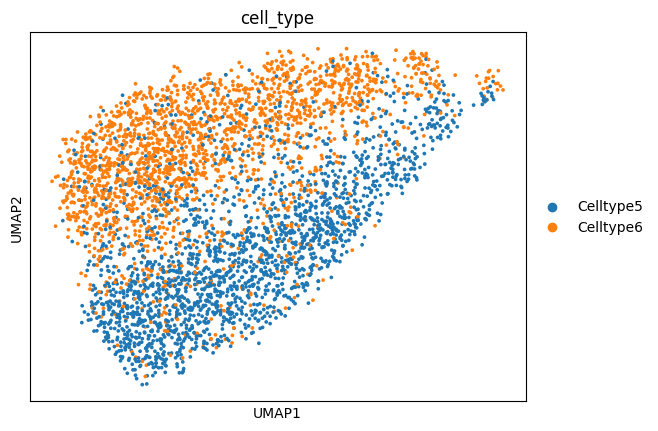

In [12]:
sc.pp.neighbors(adata, n_neighbors=5, use_rep='jepa_emb')
sc.tl.umap(adata)

# Plot the UMAP
sc.pl.umap(adata, color='cell_type')

### 3.1.3 Logistic regression

In [13]:
classification_metrics(adata, label_col='cell_type', classifier='logistic')

Test Accuracy: 0.93
Test F1 Score: 0.93
Train Accuracy: 0.95
Train F1 Score: 0.95


{'test_accuracy': 0.9299516908212561,
 'test_f1': 0.9299157124213789,
 'train_accuracy': 0.9528843249773482,
 'train_f1': 0.9528775179157386}

### 3.1.4 KNeighborsClassifier

In [14]:
classification_metrics(adata, label_col='cell_type', classifier='knn', n_neighbors=5)

Test Accuracy: 0.84
Test F1 Score: 0.84
Train Accuracy: 0.90
Train F1 Score: 0.90


{'test_accuracy': 0.8405797101449275,
 'test_f1': 0.8405797101449275,
 'train_accuracy': 0.8964059196617337,
 'train_f1': 0.8964135795529408}

### 3.1.5 nmi&ari

In [15]:
clustering_metrics(adata,label_col='cell_type')

INFO:jax._src.xla_bridge:Unable to initialize backend 'cuda': 
INFO:jax._src.xla_bridge:Unable to initialize backend 'rocm': module 'jaxlib.xla_extension' has no attribute 'GpuAllocatorConfig'
INFO:jax._src.xla_bridge:Unable to initialize backend 'tpu': INTERNAL: Failed to open libtpu.so: libtpu.so: cannot open shared object file: No such file or directory
NMI (Normalized Mutual Information): 0.0010122496854710731
ARI (Adjusted Rand Index): 0.001496256329349342


{'nmi': 0.0010122496854710731, 'ari': 0.001496256329349342}

### 3.1.5 nmi&ari on pca

In [16]:
import scib_metrics as sm
reduced_embeddings=sc.pp.pca(adata.obsm['jepa_emb'],n_comps=3)
sm.nmi_ari_cluster_labels_kmeans(reduced_embeddings, adata.obs['cell_type'])

{'nmi': 0.0010122496854710731, 'ari': 0.001496256329349342}

## 3.2 Cell Type CLS

In [17]:
params['emb']['retrieve_cell'] = True
params['emb']['retrieve_niche'] = False
params['emb']['retrieve_gene'] = False
params['emb']['weighted_average']=False
params['emb']['average']=False
params['emb']['cls']=True
adata = evaluation(params, train_dataset, test_dataset)

INFO:root:GeneTransformerEncoder(
  (gene_embed): Embedding(1108, 768, padding_idx=0)
  (seg_embed): Embedding(3, 768, padding_idx=0)
  (blocks): ModuleList(
    (0-2): 3 x Block(
      (norm1): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
      (attn): Attention(
        (qkv): Linear(in_features=768, out_features=2304, bias=True)
        (attn_drop): Dropout(p=0.0, inplace=False)
        (proj): Linear(in_features=768, out_features=768, bias=True)
        (proj_drop): Dropout(p=0.0, inplace=False)
      )
      (drop_path): Identity()
      (norm2): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
      (mlp): MLP(
        (fc1): Linear(in_features=768, out_features=3072, bias=True)
        (act): GELU(approximate='none')
        (fc2): Linear(in_features=3072, out_features=768, bias=True)
        (drop): Dropout(p=0.0, inplace=False)
      )
    )
  )
  (norm): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
)


/nfs/team361/mv10/.jepa/lib/python3.10/site-packages/torch/utils/data/dataloader.py:558: UserWarning: This DataLoader will create 18 worker processes in total. Our suggested max number of worker in current system is 12, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(_create_warning_msg(


INFO:root:loaded pretrained encoder from epoch 15 with msg: <All keys matched successfully>
INFO:root:loaded pretrained encoder from epoch 15 with msg: <All keys matched successfully>
['encoder', 'predictor', 'target_encoder', 'opt', 'scaler', 'epoch', 'loss', 'batch_size', 'world_size', 'lr']
INFO:root:loaded pretrained encoder from epoch 15 with msg: <All keys matched successfully>


/usr/lib/python3.10/multiprocessing/popen_fork.py:66: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  self.pid = os.fork()
166it [00:04, 43.48it/s]/usr/lib/python3.10/multiprocessing/popen_fork.py:66: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  self.pid = os.fork()
166it [00:04, 38.87it/s]
42it [00:01, 33.20it/s]
... storing 'split' as categorical
... storing 'label_name' as categorical
... storing 'retrieve_label' as categorical
... storing 'cell_type' as categorical


AnnData has been successfully saved at: logs/Simulated_data_pred_depth_1_pred_emb_dim_768_enc_depth_3_n_targets_4_n_contexts_1_target_mask_size_19_context_mask_size_361_num_epochs_15_just_cell_just_neighborhood_subset_Celltype5_Celltype6/extracted_features/cell_embedding_cls.h5ad


### 3.2.1 Feature Analysis

In [18]:
similarity_matrix = cosine_similarity(adata.obsm['jepa_emb'])
similarity_matrix

array([[1.        , 0.9999889 , 0.99986595, ..., 0.999882  , 0.9998824 ,
        0.99995744],
       [0.9999889 , 0.9999999 , 0.9998826 , ..., 0.9998971 , 0.99986804,
        0.99996626],
       [0.99986595, 0.9998826 , 1.0000001 , ..., 0.9999903 , 0.9995345 ,
        0.9999608 ],
       ...,
       [0.999882  , 0.9998971 , 0.9999903 , ..., 0.9999997 , 0.9995667 ,
        0.9999677 ],
       [0.9998824 , 0.99986804, 0.9995345 , ..., 0.9995667 , 0.99999994,
        0.9997383 ],
       [0.99995744, 0.99996626, 0.9999608 , ..., 0.9999677 , 0.9997383 ,
        0.99999994]], dtype=float32)

### 3.2.2 Umap

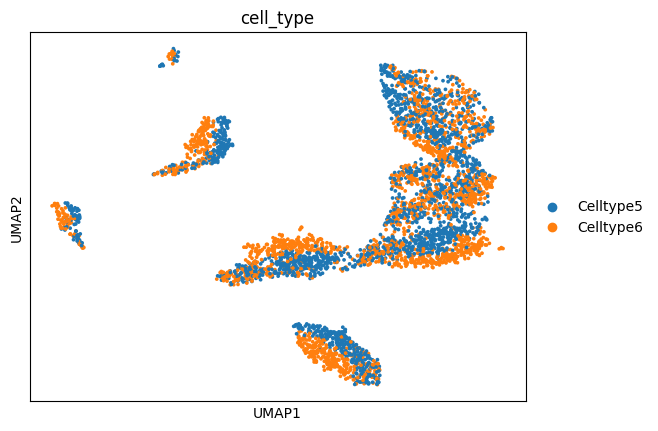

In [19]:
sc.pp.neighbors(adata, n_neighbors=5, use_rep='jepa_emb')
sc.tl.umap(adata)

# Plot the UMAP
sc.pl.umap(adata, color='cell_type')

### 3.2.3 Logistic regression

In [20]:
classification_metrics(adata, label_col='cell_type', classifier='logistic')

Test Accuracy: 0.83
Test F1 Score: 0.83
Train Accuracy: 0.84
Train F1 Score: 0.84


{'test_accuracy': 0.8272946859903382,
 'test_f1': 0.8270053398901209,
 'train_accuracy': 0.8396254907882815,
 'train_f1': 0.8392542045604331}

### 3.2.4 KNeighborsClassifier

In [21]:
classification_metrics(adata, label_col='cell_type', classifier='knn', n_neighbors=5)

Test Accuracy: 0.81
Test F1 Score: 0.81
Train Accuracy: 0.89
Train F1 Score: 0.89


{'test_accuracy': 0.8055555555555556,
 'test_f1': 0.8055024964917784,
 'train_accuracy': 0.8945937783147085,
 'train_f1': 0.8945866366881172}

### 3.2.5 nmi&ari

In [22]:
clustering_metrics(adata,label_col='cell_type')

NMI (Normalized Mutual Information): 0.0003011457741578061
ARI (Adjusted Rand Index): 0.00047361971845211556


{'nmi': 0.0003011457741578061, 'ari': 0.00047361971845211556}

## 3.3 Cell Type weighted_average

In [23]:
params['emb']['retrieve_cell'] = True
params['emb']['retrieve_niche'] = False
params['emb']['retrieve_gene'] = False
params['emb']['weighted_average']=True
params['emb']['average']=False
params['emb']['cls']=False
adata = evaluation(params, train_dataset, test_dataset)

INFO:root:GeneTransformerEncoder(
  (gene_embed): Embedding(1108, 768, padding_idx=0)
  (seg_embed): Embedding(3, 768, padding_idx=0)
  (blocks): ModuleList(
    (0-2): 3 x Block(
      (norm1): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
      (attn): Attention(
        (qkv): Linear(in_features=768, out_features=2304, bias=True)
        (attn_drop): Dropout(p=0.0, inplace=False)
        (proj): Linear(in_features=768, out_features=768, bias=True)
        (proj_drop): Dropout(p=0.0, inplace=False)
      )
      (drop_path): Identity()
      (norm2): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
      (mlp): MLP(
        (fc1): Linear(in_features=768, out_features=3072, bias=True)
        (act): GELU(approximate='none')
        (fc2): Linear(in_features=3072, out_features=768, bias=True)
        (drop): Dropout(p=0.0, inplace=False)
      )
    )
  )
  (norm): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
)


/nfs/team361/mv10/.jepa/lib/python3.10/site-packages/torch/utils/data/dataloader.py:558: UserWarning: This DataLoader will create 18 worker processes in total. Our suggested max number of worker in current system is 12, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(_create_warning_msg(


INFO:root:loaded pretrained encoder from epoch 15 with msg: <All keys matched successfully>
INFO:root:loaded pretrained encoder from epoch 15 with msg: <All keys matched successfully>
['encoder', 'predictor', 'target_encoder', 'opt', 'scaler', 'epoch', 'loss', 'batch_size', 'world_size', 'lr']
INFO:root:loaded pretrained encoder from epoch 15 with msg: <All keys matched successfully>


/usr/lib/python3.10/multiprocessing/popen_fork.py:66: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  self.pid = os.fork()
166it [00:04, 43.33it/s]/usr/lib/python3.10/multiprocessing/popen_fork.py:66: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  self.pid = os.fork()
166it [00:04, 38.53it/s]
42it [00:01, 33.36it/s]
... storing 'split' as categorical
... storing 'label_name' as categorical
... storing 'retrieve_label' as categorical
... storing 'cell_type' as categorical


AnnData has been successfully saved at: logs/Simulated_data_pred_depth_1_pred_emb_dim_768_enc_depth_3_n_targets_4_n_contexts_1_target_mask_size_19_context_mask_size_361_num_epochs_15_just_cell_just_neighborhood_subset_Celltype5_Celltype6/extracted_features/cell_embedding_weighted_average.h5ad


### 3.3.1 Feature Analysis

In [24]:
similarity_matrix = cosine_similarity(adata.obsm['jepa_emb'])
similarity_matrix

array([[0.9999999 , 0.99954075, 0.9965342 , ..., 0.99563   , 0.9970983 ,
        0.9986358 ],
       [0.99954075, 1.0000001 , 0.9972802 , ..., 0.9964662 , 0.9963127 ,
        0.9990469 ],
       [0.9965342 , 0.9972802 , 0.9999999 , ..., 0.99959135, 0.98858094,
        0.9990269 ],
       ...,
       [0.99563   , 0.9964662 , 0.99959135, ..., 0.99999994, 0.9869243 ,
        0.9985577 ],
       [0.9970983 , 0.9963127 , 0.98858094, ..., 0.9869243 , 1.        ,
        0.99300873],
       [0.9986358 , 0.9990469 , 0.9990269 , ..., 0.9985577 , 0.99300873,
        0.9999999 ]], dtype=float32)

### 3.3.2 Umap

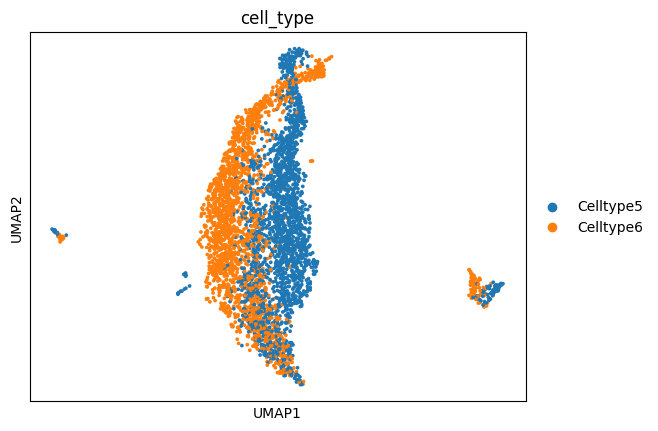

In [25]:
sc.pp.neighbors(adata, n_neighbors=5, use_rep='jepa_emb')
sc.tl.umap(adata)

# Plot the UMAP
sc.pl.umap(adata, color='cell_type')

### 3.3.3 Logistic regression

In [26]:
classification_metrics(adata, label_col='cell_type', classifier='logistic')

Test Accuracy: 0.92
Test F1 Score: 0.92
Train Accuracy: 0.93
Train F1 Score: 0.93


{'test_accuracy': 0.9239130434782609,
 'test_f1': 0.9238780729134848,
 'train_accuracy': 0.9296285110238599,
 'train_f1': 0.9296207352546445}

### 3.3.4 KNN

In [27]:
classification_metrics(adata, label_col='cell_type', classifier='knn', n_neighbors=5)

Test Accuracy: 0.85
Test F1 Score: 0.85
Train Accuracy: 0.91
Train F1 Score: 0.91


{'test_accuracy': 0.8478260869565217,
 'test_f1': 0.8477479269843752,
 'train_accuracy': 0.907278767743884,
 'train_f1': 0.9072705379412491}

### 3.3.5 nmi&ari

In [28]:
clustering_metrics(adata,label_col='cell_type')

NMI (Normalized Mutual Information): 0.0006049473727178851
ARI (Adjusted Rand Index): 0.0008966903724042509


{'nmi': 0.0006049473727178851, 'ari': 0.0008966903724042509}

## 3.4 Niche Type Average

In [29]:
params['emb']['retrieve_cell'] = False
params['emb']['retrieve_niche'] = True
params['emb']['retrieve_gene'] = False
params['emb']['weighted_average']=False
params['emb']['average']=True
params['emb']['cls']=False
params['data']['just_cell'] = True
params['data']['just_neighborhood'] = True
adata = evaluation(params, train_dataset, test_dataset)

INFO:root:GeneTransformerEncoder(
  (gene_embed): Embedding(1108, 768, padding_idx=0)
  (seg_embed): Embedding(3, 768, padding_idx=0)
  (blocks): ModuleList(
    (0-2): 3 x Block(
      (norm1): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
      (attn): Attention(
        (qkv): Linear(in_features=768, out_features=2304, bias=True)
        (attn_drop): Dropout(p=0.0, inplace=False)
        (proj): Linear(in_features=768, out_features=768, bias=True)
        (proj_drop): Dropout(p=0.0, inplace=False)
      )
      (drop_path): Identity()
      (norm2): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
      (mlp): MLP(
        (fc1): Linear(in_features=768, out_features=3072, bias=True)
        (act): GELU(approximate='none')
        (fc2): Linear(in_features=3072, out_features=768, bias=True)
        (drop): Dropout(p=0.0, inplace=False)
      )
    )
  )
  (norm): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
)


/nfs/team361/mv10/.jepa/lib/python3.10/site-packages/torch/utils/data/dataloader.py:558: UserWarning: This DataLoader will create 18 worker processes in total. Our suggested max number of worker in current system is 12, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(_create_warning_msg(


INFO:root:loaded pretrained encoder from epoch 15 with msg: <All keys matched successfully>
INFO:root:loaded pretrained encoder from epoch 15 with msg: <All keys matched successfully>
['encoder', 'predictor', 'target_encoder', 'opt', 'scaler', 'epoch', 'loss', 'batch_size', 'world_size', 'lr']
INFO:root:loaded pretrained encoder from epoch 15 with msg: <All keys matched successfully>


/usr/lib/python3.10/multiprocessing/popen_fork.py:66: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  self.pid = os.fork()
164it [00:04, 40.86it/s]/usr/lib/python3.10/multiprocessing/popen_fork.py:66: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  self.pid = os.fork()
166it [00:04, 38.35it/s]
42it [00:01, 30.47it/s]
... storing 'split' as categorical
... storing 'label_name' as categorical
... storing 'retrieve_label' as categorical
... storing 'niche_type' as categorical


AnnData has been successfully saved at: logs/Simulated_data_pred_depth_1_pred_emb_dim_768_enc_depth_3_n_targets_4_n_contexts_1_target_mask_size_19_context_mask_size_361_num_epochs_15_just_cell_just_neighborhood_subset_Celltype5_Celltype6/extracted_features/niche_embedding_average.h5ad


### 3.4.1 Feature Analysis

In [30]:
similarity_matrix = cosine_similarity(adata.obsm['jepa_emb'])
similarity_matrix

array([[1.        , 0.99990374, 0.9998456 , ..., 0.9998605 , 0.999738  ,
        0.99989176],
       [0.99990374, 1.        , 0.9998553 , ..., 0.9998642 , 0.9997406 ,
        0.99990475],
       [0.9998456 , 0.9998553 , 1.        , ..., 0.99997556, 0.9995008 ,
        0.999936  ],
       ...,
       [0.9998605 , 0.9998642 , 0.99997556, ..., 1.        , 0.99952686,
        0.9999392 ],
       [0.999738  , 0.9997406 , 0.9995008 , ..., 0.99952686, 1.0000001 ,
        0.9996369 ],
       [0.99989176, 0.99990475, 0.999936  , ..., 0.9999392 , 0.9996369 ,
        0.9999999 ]], dtype=float32)

### 3.4.2 Umap

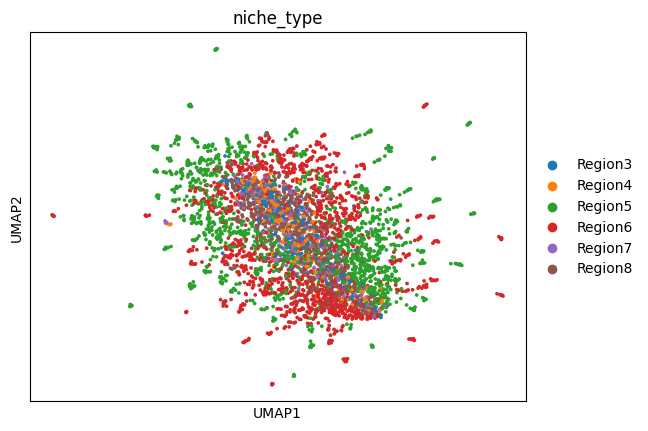

In [31]:
sc.pp.neighbors(adata, n_neighbors=5, use_rep='jepa_emb')
sc.tl.umap(adata)

# Plot the UMAP
sc.pl.umap(adata, color='niche_type')

### 3.4.3 Logistic regression

In [32]:
classification_metrics(adata, label_col='niche_type', classifier='logistic')

Test Accuracy: 0.67
Test F1 Score: 0.58
Train Accuracy: 0.66
Train F1 Score: 0.56


/nfs/team361/mv10/.jepa/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


{'test_accuracy': 0.6727053140096618,
 'test_f1': 0.5781934800088699,
 'train_accuracy': 0.6635457565690124,
 'train_f1': 0.5577298502780073}

### 3.4.4 KNN

In [33]:
classification_metrics(adata, label_col='niche_type', classifier='knn', n_neighbors=5)

Test Accuracy: 0.78
Test F1 Score: 0.78
Train Accuracy: 0.89
Train F1 Score: 0.88


{'test_accuracy': 0.7801932367149759,
 'test_f1': 0.7778840844169345,
 'train_accuracy': 0.8867411658109332,
 'train_f1': 0.8839021682984504}

### 3.4.5 nmi&ari

In [34]:
clustering_metrics(adata,label_col='niche_type')

NMI (Normalized Mutual Information): 0.003525865680837117
ARI (Adjusted Rand Index): 0.002547736190210859


{'nmi': 0.003525865680837117, 'ari': 0.002547736190210859}

### 3.4.5 nmi&ari on pca

In [35]:
import scib_metrics as sm
reduced_embeddings=sc.pp.pca(adata.obsm['jepa_emb'],n_comps=2)
sm.nmi_ari_cluster_labels_kmeans(reduced_embeddings, adata.obs['niche_type'])

{'nmi': 0.004109060336395729, 'ari': 0.00373469928299969}

## 3.5 Niche Type CLS

In [36]:
params['emb']['retrieve_cell'] = False
params['emb']['retrieve_niche'] = True
params['emb']['retrieve_gene'] = False
params['emb']['weighted_average']=False
params['emb']['average']=False
params['emb']['cls']=True
adata = evaluation(params, train_dataset, test_dataset)

INFO:root:GeneTransformerEncoder(
  (gene_embed): Embedding(1108, 768, padding_idx=0)
  (seg_embed): Embedding(3, 768, padding_idx=0)
  (blocks): ModuleList(
    (0-2): 3 x Block(
      (norm1): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
      (attn): Attention(
        (qkv): Linear(in_features=768, out_features=2304, bias=True)
        (attn_drop): Dropout(p=0.0, inplace=False)
        (proj): Linear(in_features=768, out_features=768, bias=True)
        (proj_drop): Dropout(p=0.0, inplace=False)
      )
      (drop_path): Identity()
      (norm2): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
      (mlp): MLP(
        (fc1): Linear(in_features=768, out_features=3072, bias=True)
        (act): GELU(approximate='none')
        (fc2): Linear(in_features=3072, out_features=768, bias=True)
        (drop): Dropout(p=0.0, inplace=False)
      )
    )
  )
  (norm): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
)


/nfs/team361/mv10/.jepa/lib/python3.10/site-packages/torch/utils/data/dataloader.py:558: UserWarning: This DataLoader will create 18 worker processes in total. Our suggested max number of worker in current system is 12, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(_create_warning_msg(


INFO:root:loaded pretrained encoder from epoch 15 with msg: <All keys matched successfully>
INFO:root:loaded pretrained encoder from epoch 15 with msg: <All keys matched successfully>
['encoder', 'predictor', 'target_encoder', 'opt', 'scaler', 'epoch', 'loss', 'batch_size', 'world_size', 'lr']
INFO:root:loaded pretrained encoder from epoch 15 with msg: <All keys matched successfully>


/usr/lib/python3.10/multiprocessing/popen_fork.py:66: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  self.pid = os.fork()
166it [00:04, 43.10it/s]/usr/lib/python3.10/multiprocessing/popen_fork.py:66: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  self.pid = os.fork()
166it [00:04, 39.50it/s]
42it [00:01, 30.72it/s]
... storing 'split' as categorical
... storing 'label_name' as categorical
... storing 'retrieve_label' as categorical
... storing 'niche_type' as categorical


AnnData has been successfully saved at: logs/Simulated_data_pred_depth_1_pred_emb_dim_768_enc_depth_3_n_targets_4_n_contexts_1_target_mask_size_19_context_mask_size_361_num_epochs_15_just_cell_just_neighborhood_subset_Celltype5_Celltype6/extracted_features/niche_embedding_cls.h5ad


### 3.5.1 Feature Analysis

In [37]:
similarity_matrix = cosine_similarity(adata.obsm['jepa_emb'])
similarity_matrix

array([[1.        , 0.9999889 , 0.99986595, ..., 0.999882  , 0.9998824 ,
        0.99995744],
       [0.9999889 , 0.9999999 , 0.9998826 , ..., 0.9998971 , 0.99986804,
        0.99996626],
       [0.99986595, 0.9998826 , 1.0000001 , ..., 0.9999903 , 0.9995345 ,
        0.9999608 ],
       ...,
       [0.999882  , 0.9998971 , 0.9999903 , ..., 0.9999997 , 0.9995667 ,
        0.9999677 ],
       [0.9998824 , 0.99986804, 0.9995345 , ..., 0.9995667 , 0.99999994,
        0.9997383 ],
       [0.99995744, 0.99996626, 0.9999608 , ..., 0.9999677 , 0.9997383 ,
        0.99999994]], dtype=float32)

### 3.5.2 Umap

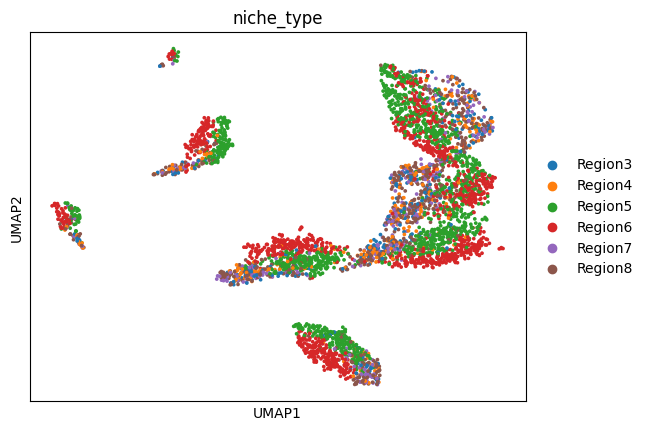

In [38]:
sc.pp.neighbors(adata, n_neighbors=5, use_rep='jepa_emb')
sc.tl.umap(adata)

# Plot the UMAP
sc.pl.umap(adata, color='niche_type')

### 3.5.3 Logistic regression

In [39]:
classification_metrics(adata, label_col='niche_type', classifier='logistic')

Test Accuracy: 0.72
Test F1 Score: 0.65
Train Accuracy: 0.70
Train F1 Score: 0.62


/nfs/team361/mv10/.jepa/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


{'test_accuracy': 0.7185990338164251,
 'test_f1': 0.6485920576740687,
 'train_accuracy': 0.6952582301419511,
 'train_f1': 0.6153183948203895}

### 3.5.4 KNN

In [40]:
classification_metrics(adata, label_col='niche_type', classifier='knn', n_neighbors=5)

Test Accuracy: 0.73
Test F1 Score: 0.72
Train Accuracy: 0.81
Train F1 Score: 0.80


{'test_accuracy': 0.7306763285024155,
 'test_f1': 0.7214940760915665,
 'train_accuracy': 0.812745394140743,
 'train_f1': 0.8019615143680009}

### 3.5.5 nmi&ari

In [41]:
clustering_metrics(adata,label_col='niche_type')

NMI (Normalized Mutual Information): 0.0030184415589515575
ARI (Adjusted Rand Index): 0.002415275569834298


{'nmi': 0.0030184415589515575, 'ari': 0.002415275569834298}

## 3.6 Niche Type weighted_average

In [42]:
params['emb']['retrieve_cell'] = False
params['emb']['retrieve_niche'] = True
params['emb']['retrieve_gene'] = False
params['emb']['weighted_average']=True
params['emb']['average']=False
params['emb']['cls']=False
adata = evaluation(params, train_dataset, test_dataset)

INFO:root:GeneTransformerEncoder(
  (gene_embed): Embedding(1108, 768, padding_idx=0)
  (seg_embed): Embedding(3, 768, padding_idx=0)
  (blocks): ModuleList(
    (0-2): 3 x Block(
      (norm1): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
      (attn): Attention(
        (qkv): Linear(in_features=768, out_features=2304, bias=True)
        (attn_drop): Dropout(p=0.0, inplace=False)
        (proj): Linear(in_features=768, out_features=768, bias=True)
        (proj_drop): Dropout(p=0.0, inplace=False)
      )
      (drop_path): Identity()
      (norm2): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
      (mlp): MLP(
        (fc1): Linear(in_features=768, out_features=3072, bias=True)
        (act): GELU(approximate='none')
        (fc2): Linear(in_features=3072, out_features=768, bias=True)
        (drop): Dropout(p=0.0, inplace=False)
      )
    )
  )
  (norm): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
)


/nfs/team361/mv10/.jepa/lib/python3.10/site-packages/torch/utils/data/dataloader.py:558: UserWarning: This DataLoader will create 18 worker processes in total. Our suggested max number of worker in current system is 12, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(_create_warning_msg(


INFO:root:loaded pretrained encoder from epoch 15 with msg: <All keys matched successfully>
INFO:root:loaded pretrained encoder from epoch 15 with msg: <All keys matched successfully>
['encoder', 'predictor', 'target_encoder', 'opt', 'scaler', 'epoch', 'loss', 'batch_size', 'world_size', 'lr']
INFO:root:loaded pretrained encoder from epoch 15 with msg: <All keys matched successfully>


/usr/lib/python3.10/multiprocessing/popen_fork.py:66: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  self.pid = os.fork()
165it [00:04, 40.75it/s]/usr/lib/python3.10/multiprocessing/popen_fork.py:66: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  self.pid = os.fork()
166it [00:05, 32.55it/s]
42it [00:01, 29.55it/s]
... storing 'split' as categorical
... storing 'label_name' as categorical
... storing 'retrieve_label' as categorical
... storing 'niche_type' as categorical


AnnData has been successfully saved at: logs/Simulated_data_pred_depth_1_pred_emb_dim_768_enc_depth_3_n_targets_4_n_contexts_1_target_mask_size_19_context_mask_size_361_num_epochs_15_just_cell_just_neighborhood_subset_Celltype5_Celltype6/extracted_features/niche_embedding_weighted_average.h5ad


### 3.6.1 Feature Analysis

In [43]:
similarity_matrix = cosine_similarity(adata.obsm['jepa_emb'])
similarity_matrix

array([[0.9999999 , 0.99954075, 0.9965342 , ..., 0.99563   , 0.9970983 ,
        0.9986358 ],
       [0.99954075, 1.0000001 , 0.9972802 , ..., 0.9964662 , 0.9963127 ,
        0.9990469 ],
       [0.9965342 , 0.9972802 , 0.9999999 , ..., 0.99959135, 0.98858094,
        0.9990269 ],
       ...,
       [0.99563   , 0.9964662 , 0.99959135, ..., 0.99999994, 0.9869243 ,
        0.9985577 ],
       [0.9970983 , 0.9963127 , 0.98858094, ..., 0.9869243 , 1.        ,
        0.99300873],
       [0.9986358 , 0.9990469 , 0.9990269 , ..., 0.9985577 , 0.99300873,
        0.9999999 ]], dtype=float32)

### 3.6.2 Umap

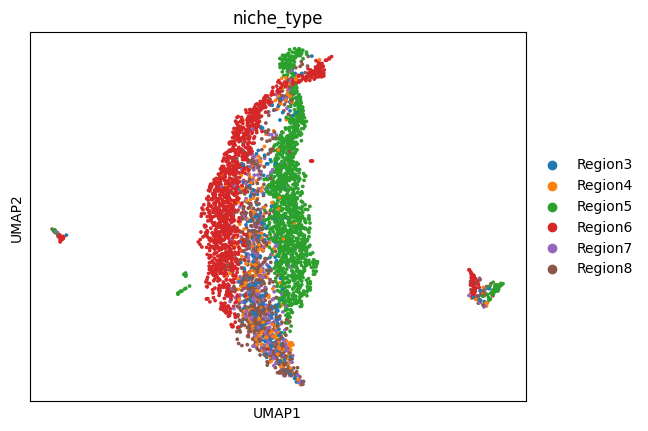

In [44]:
sc.pp.neighbors(adata, n_neighbors=5, use_rep='jepa_emb')
sc.tl.umap(adata)

# Plot the UMAP
sc.pl.umap(adata, color='niche_type')

### 3.6.3 Logistic regression

In [45]:
classification_metrics(adata, label_col='niche_type', classifier='logistic')

Test Accuracy: 0.82
Test F1 Score: 0.76
Train Accuracy: 0.78
Train F1 Score: 0.72


/nfs/team361/mv10/.jepa/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


{'test_accuracy': 0.8176328502415459,
 'test_f1': 0.7591724224275157,
 'train_accuracy': 0.784959226819692,
 'train_f1': 0.7199513716934491}

### 3.6.4 KNN

In [46]:
classification_metrics(adata, label_col='niche_type', classifier='knn', n_neighbors=5)

Test Accuracy: 0.78
Test F1 Score: 0.75
Train Accuracy: 0.84
Train F1 Score: 0.82


{'test_accuracy': 0.7777777777777778,
 'test_f1': 0.7468189861636977,
 'train_accuracy': 0.8375113258834189,
 'train_f1': 0.8217575582235064}

### 3.6.5 nmi&ari

In [47]:
clustering_metrics(adata,label_col='niche_type')

NMI (Normalized Mutual Information): 0.069913988912254
ARI (Adjusted Rand Index): 0.05097696807313868


{'nmi': 0.069913988912254, 'ari': 0.05097696807313868}

## 3.7 Retrieve Gene

In [48]:
params['emb']['retrieve_cell'] = False
params['emb']['retrieve_niche'] = False
params['emb']['retrieve_gene'] = True
params['emb']['weighted_average']=False
params['emb']['average']=True
params['emb']['cls']=False
params['emb']['gene_id']=332 #change this for different value to get different gene_emb'
adata = evaluation(params, train_dataset, test_dataset)

INFO:root:GeneTransformerEncoder(
  (gene_embed): Embedding(1108, 768, padding_idx=0)
  (seg_embed): Embedding(3, 768, padding_idx=0)
  (blocks): ModuleList(
    (0-2): 3 x Block(
      (norm1): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
      (attn): Attention(
        (qkv): Linear(in_features=768, out_features=2304, bias=True)
        (attn_drop): Dropout(p=0.0, inplace=False)
        (proj): Linear(in_features=768, out_features=768, bias=True)
        (proj_drop): Dropout(p=0.0, inplace=False)
      )
      (drop_path): Identity()
      (norm2): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
      (mlp): MLP(
        (fc1): Linear(in_features=768, out_features=3072, bias=True)
        (act): GELU(approximate='none')
        (fc2): Linear(in_features=3072, out_features=768, bias=True)
        (drop): Dropout(p=0.0, inplace=False)
      )
    )
  )
  (norm): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
)


/nfs/team361/mv10/.jepa/lib/python3.10/site-packages/torch/utils/data/dataloader.py:558: UserWarning: This DataLoader will create 18 worker processes in total. Our suggested max number of worker in current system is 12, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(_create_warning_msg(


INFO:root:loaded pretrained encoder from epoch 15 with msg: <All keys matched successfully>
INFO:root:loaded pretrained encoder from epoch 15 with msg: <All keys matched successfully>
['encoder', 'predictor', 'target_encoder', 'opt', 'scaler', 'epoch', 'loss', 'batch_size', 'world_size', 'lr']
INFO:root:loaded pretrained encoder from epoch 15 with msg: <All keys matched successfully>


/usr/lib/python3.10/multiprocessing/popen_fork.py:66: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  self.pid = os.fork()
163it [00:04, 41.86it/s]/usr/lib/python3.10/multiprocessing/popen_fork.py:66: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  self.pid = os.fork()
166it [00:04, 38.29it/s]
42it [00:01, 33.30it/s]
... storing 'split' as categorical
... storing 'label_name' as categorical
... storing 'retrieve_label' as categorical
... storing 'cell_type' as categorical


AnnData has been successfully saved at: logs/Simulated_data_pred_depth_1_pred_emb_dim_768_enc_depth_3_n_targets_4_n_contexts_1_target_mask_size_19_context_mask_size_361_num_epochs_15_just_cell_just_neighborhood_subset_Celltype5_Celltype6/extracted_features/gene_embedding_gene_id_332_average.h5ad


### 3.7.1 Feature Analysis

In [49]:
similarity_matrix = cosine_similarity(adata.obsm['jepa_emb'])
similarity_matrix

array([[0.       , 0.       , 0.       , ..., 0.       , 0.       ,
        0.       ],
       [0.       , 0.9999999, 0.       , ..., 0.       , 0.9998753,
        0.       ],
       [0.       , 0.       , 0.       , ..., 0.       , 0.       ,
        0.       ],
       ...,
       [0.       , 0.       , 0.       , ..., 0.       , 0.       ,
        0.       ],
       [0.       , 0.9998753, 0.       , ..., 0.       , 1.0000002,
        0.       ],
       [0.       , 0.       , 0.       , ..., 0.       , 0.       ,
        0.       ]], dtype=float32)

### 3.7.2 Umap

In [50]:
adata = adata[adata.obs['gene_count']!=0]

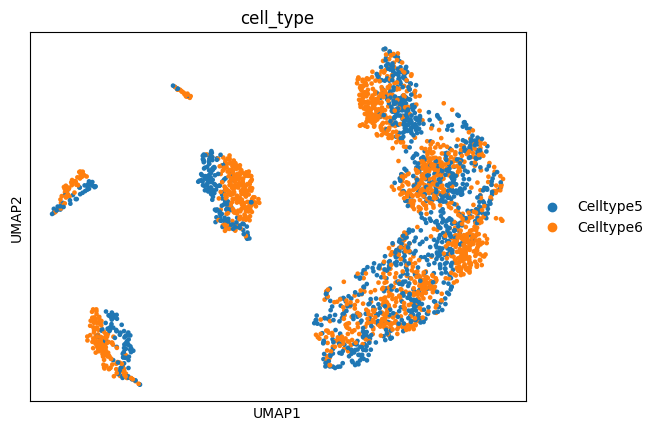

In [51]:
sc.pp.neighbors(adata, n_neighbors=5, use_rep='jepa_emb')
sc.tl.umap(adata)

# Plot the UMAP
sc.pl.umap(adata, color='cell_type')

# 4.Model Training With just_cell as True

## 4.1 Train Model

In [52]:
params['data']['just_cell'] = True
params['data']['just_neighborhood'] = False
train(params, train_dataset, test_dataset)

INFO:root:Initialized (rank/world-size) 0/1
INFO:root:GeneTransformerEncoder(
  (gene_embed): Embedding(1108, 768, padding_idx=0)
  (seg_embed): Embedding(3, 768, padding_idx=0)
  (blocks): ModuleList(
    (0-2): 3 x Block(
      (norm1): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
      (attn): Attention(
        (qkv): Linear(in_features=768, out_features=2304, bias=True)
        (attn_drop): Dropout(p=0.0, inplace=False)
        (proj): Linear(in_features=768, out_features=768, bias=True)
        (proj_drop): Dropout(p=0.0, inplace=False)
      )
      (drop_path): Identity()
      (norm2): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
      (mlp): MLP(
        (fc1): Linear(in_features=768, out_features=3072, bias=True)
        (act): GELU(approximate='none')
        (fc2): Linear(in_features=3072, out_features=768, bias=True)
        (drop): Dropout(p=0.0, inplace=False)
      )
    )
  )
  (norm): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
)
INFO:root

/nfs/team361/mv10/.jepa/lib/python3.10/site-packages/torch/utils/data/dataloader.py:558: UserWarning: This DataLoader will create 18 worker processes in total. Our suggested max number of worker in current system is 12, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(_create_warning_msg(
/usr/lib/python3.10/multiprocessing/popen_fork.py:66: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  self.pid = os.fork()


INFO:root:[1,     0] loss: 0.531 masks: 285.0 20.0 [wd: 4.00e-02] [lr: 4.99e-05] [mem: 5.08e+03] (36.6 ms)
INFO:root:[1,     0] grad_stats: [1.42e-01 1.26e-01] (3.61e-04, 1.66e-01)
INFO:root:[1,    10] loss: 0.333 masks: 285.0 19.7 [wd: 4.00e-02] [lr: 4.94e-05] [mem: 5.08e+03] (24.8 ms)
INFO:root:[1,    10] grad_stats: [8.06e-03 7.14e-03] (2.04e-05, 9.69e-03)
INFO:root:[1,    20] loss: 0.287 masks: 285.0 19.7 [wd: 4.01e-02] [lr: 4.88e-05] [mem: 5.08e+03] (23.9 ms)
INFO:root:[1,    20] grad_stats: [2.59e-03 2.55e-03] (6.91e-06, 3.32e-03)
INFO:root:[1,    30] loss: 0.265 masks: 285.0 19.7 [wd: 4.01e-02] [lr: 4.82e-05] [mem: 5.08e+03] (23.6 ms)
INFO:root:[1,    30] grad_stats: [1.31e-03 1.30e-03] (4.23e-06, 1.66e-03)
INFO:root:[1,    40] loss: 0.253 masks: 285.0 19.8 [wd: 4.02e-02] [lr: 4.76e-05] [mem: 5.08e+03] (23.6 ms)
INFO:root:[1,    40] grad_stats: [9.02e-04 9.02e-04] (3.27e-06, 1.15e-03)
INFO:root:[1,    50] loss: 0.246 masks: 285.0 19.7 [wd: 4.04e-02] [lr: 4.70e-05] [mem: 5.08e+03

/usr/lib/python3.10/multiprocessing/popen_fork.py:66: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  self.pid = os.fork()


INFO:root:avg. loss 0.220
INFO:root:Epoch 2
INFO:root:[2,     0] loss: 0.201 masks: 285.0 20.0 [wd: 4.40e-02] [lr: 4.01e-05] [mem: 5.08e+03] (26.6 ms)
INFO:root:[2,     0] grad_stats: [1.03e-03 1.07e-03] (3.28e-06, 1.33e-03)
INFO:root:[2,    10] loss: 0.201 masks: 285.0 20.0 [wd: 4.45e-02] [lr: 3.96e-05] [mem: 5.08e+03] (24.1 ms)
INFO:root:[2,    10] grad_stats: [9.90e-04 9.66e-04] (3.28e-06, 1.20e-03)
INFO:root:[2,    20] loss: 0.201 masks: 285.0 20.0 [wd: 4.50e-02] [lr: 3.90e-05] [mem: 5.08e+03] (23.8 ms)
INFO:root:[2,    20] grad_stats: [1.11e-03 1.12e-03] (3.52e-06, 1.42e-03)
INFO:root:[2,    30] loss: 0.200 masks: 285.0 19.9 [wd: 4.55e-02] [lr: 3.84e-05] [mem: 5.08e+03] (23.6 ms)
INFO:root:[2,    30] grad_stats: [9.22e-04 9.34e-04] (3.19e-06, 1.19e-03)
INFO:root:[2,    40] loss: 0.200 masks: 285.0 19.8 [wd: 4.61e-02] [lr: 3.78e-05] [mem: 5.08e+03] (23.5 ms)
INFO:root:[2,    40] grad_stats: [7.27e-04 8.26e-04] (2.88e-06, 9.91e-04)
INFO:root:[2,    50] loss: 0.200 masks: 285.0 19.7 

# 5. Analysis With just_cell as True

## 5.1 Cell Type Average

In [53]:
params['emb']['retrieve_cell'] = True
params['emb']['retrieve_niche'] = False
params['emb']['retrieve_gene'] = False
params['emb']['weighted_average']=False
params['emb']['average']=True
params['emb']['cls']=False
params['data']['just_cell'] = True
params['data']['just_neighborhood'] = False
adata = evaluation(params, train_dataset, test_dataset)

INFO:root:GeneTransformerEncoder(
  (gene_embed): Embedding(1108, 768, padding_idx=0)
  (seg_embed): Embedding(3, 768, padding_idx=0)
  (blocks): ModuleList(
    (0-2): 3 x Block(
      (norm1): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
      (attn): Attention(
        (qkv): Linear(in_features=768, out_features=2304, bias=True)
        (attn_drop): Dropout(p=0.0, inplace=False)
        (proj): Linear(in_features=768, out_features=768, bias=True)
        (proj_drop): Dropout(p=0.0, inplace=False)
      )
      (drop_path): Identity()
      (norm2): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
      (mlp): MLP(
        (fc1): Linear(in_features=768, out_features=3072, bias=True)
        (act): GELU(approximate='none')
        (fc2): Linear(in_features=3072, out_features=768, bias=True)
        (drop): Dropout(p=0.0, inplace=False)
      )
    )
  )
  (norm): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
)
INFO:root:loaded pretrained encoder from epoch 15 wit

166it [00:01, 96.91it/s] 
42it [00:00, 76.24it/s]
... storing 'split' as categorical
... storing 'label_name' as categorical
... storing 'retrieve_label' as categorical
... storing 'cell_type' as categorical


AnnData has been successfully saved at: logs/Simulated_data_pred_depth_1_pred_emb_dim_768_enc_depth_3_n_targets_4_n_contexts_1_target_mask_size_19_context_mask_size_361_num_epochs_15_just_cell_subset_Celltype5_Celltype6/extracted_features/cell_embedding_average.h5ad


### 5.1.1 Feature Analysis

In [54]:
similarity_matrix = cosine_similarity(adata.obsm['jepa_emb'])
similarity_matrix

array([[1.0000001 , 0.9989857 , 0.99884486, ..., 0.99865484, 0.9990409 ,
        0.99894136],
       [0.9989857 , 1.        , 0.9989402 , ..., 0.9987333 , 0.9990431 ,
        0.99905765],
       [0.99884486, 0.9989402 , 1.0000005 , ..., 0.99866164, 0.99892044,
        0.99883664],
       ...,
       [0.99865484, 0.9987333 , 0.99866164, ..., 1.        , 0.9987452 ,
        0.9988177 ],
       [0.9990409 , 0.9990431 , 0.99892044, ..., 0.9987452 , 1.0000002 ,
        0.9989834 ],
       [0.99894136, 0.99905765, 0.99883664, ..., 0.9988177 , 0.9989834 ,
        1.        ]], dtype=float32)

### 5.1.2 Umap

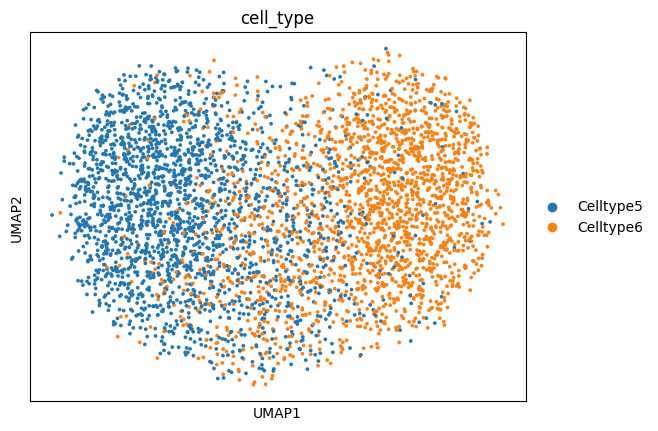

In [55]:
sc.pp.neighbors(adata, n_neighbors=5, use_rep='jepa_emb')
sc.tl.umap(adata)

# Plot the UMAP
sc.pl.umap(adata, color='cell_type')

### 5.1.3 Logistic regression

In [56]:
classification_metrics(adata, label_col='cell_type', classifier='logistic')

Test Accuracy: 0.92
Test F1 Score: 0.92
Train Accuracy: 0.95
Train F1 Score: 0.95


{'test_accuracy': 0.9239130434782609,
 'test_f1': 0.9239135983852271,
 'train_accuracy': 0.9504681365146481,
 'train_f1': 0.9504698548486357}

### 5.1.4 KNN

In [57]:
classification_metrics(adata, label_col='cell_type', classifier='knn', n_neighbors=5)

Test Accuracy: 0.84
Test F1 Score: 0.84
Train Accuracy: 0.90
Train F1 Score: 0.90


{'test_accuracy': 0.8429951690821256,
 'test_f1': 0.8429970011639357,
 'train_accuracy': 0.9000302023557838,
 'train_f1': 0.899996301710403}

### 5.1.5 nmi&ari

In [58]:
clustering_metrics(adata,label_col='cell_type')

NMI (Normalized Mutual Information): 0.00012944243298828543
ARI (Adjusted Rand Index): 0.00010105927418221176


{'nmi': 0.00012944243298828543, 'ari': 0.00010105927418221176}

### 5.1.5 nmi&ari on pca

In [59]:
import scib_metrics as sm
reduced_embeddings=sc.pp.pca(adata.obsm['jepa_emb'],n_comps=2)
sm.nmi_ari_cluster_labels_kmeans(reduced_embeddings, adata.obs['cell_type'])

{'nmi': 0.4339325697821866, 'ari': 0.40759931259295656}

## 5.2 Cell Type CLS

In [60]:
params['emb']['retrieve_cell'] = True
params['emb']['retrieve_niche'] = False
params['emb']['retrieve_gene'] = False
params['emb']['weighted_average']=False
params['emb']['average']=False
params['emb']['cls']=True
params['data']['just_cell'] = True
params['data']['just_neighborhood'] = False
adata = evaluation(params, train_dataset, test_dataset)

INFO:root:GeneTransformerEncoder(
  (gene_embed): Embedding(1108, 768, padding_idx=0)
  (seg_embed): Embedding(3, 768, padding_idx=0)
  (blocks): ModuleList(
    (0-2): 3 x Block(
      (norm1): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
      (attn): Attention(
        (qkv): Linear(in_features=768, out_features=2304, bias=True)
        (attn_drop): Dropout(p=0.0, inplace=False)
        (proj): Linear(in_features=768, out_features=768, bias=True)
        (proj_drop): Dropout(p=0.0, inplace=False)
      )
      (drop_path): Identity()
      (norm2): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
      (mlp): MLP(
        (fc1): Linear(in_features=768, out_features=3072, bias=True)
        (act): GELU(approximate='none')
        (fc2): Linear(in_features=3072, out_features=768, bias=True)
        (drop): Dropout(p=0.0, inplace=False)
      )
    )
  )
  (norm): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
)


/nfs/team361/mv10/.jepa/lib/python3.10/site-packages/torch/utils/data/dataloader.py:558: UserWarning: This DataLoader will create 18 worker processes in total. Our suggested max number of worker in current system is 12, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(_create_warning_msg(


INFO:root:loaded pretrained encoder from epoch 15 with msg: <All keys matched successfully>
INFO:root:loaded pretrained encoder from epoch 15 with msg: <All keys matched successfully>
['encoder', 'predictor', 'target_encoder', 'opt', 'scaler', 'epoch', 'loss', 'batch_size', 'world_size', 'lr']
INFO:root:loaded pretrained encoder from epoch 15 with msg: <All keys matched successfully>


/usr/lib/python3.10/multiprocessing/popen_fork.py:66: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  self.pid = os.fork()
166it [00:01, 163.37it/s]/usr/lib/python3.10/multiprocessing/popen_fork.py:66: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  self.pid = os.fork()
166it [00:01, 99.60it/s] 
42it [00:00, 76.26it/s]
... storing 'split' as categorical
... storing 'label_name' as categorical
... storing 'retrieve_label' as categorical
... storing 'cell_type' as categorical


AnnData has been successfully saved at: logs/Simulated_data_pred_depth_1_pred_emb_dim_768_enc_depth_3_n_targets_4_n_contexts_1_target_mask_size_19_context_mask_size_361_num_epochs_15_just_cell_subset_Celltype5_Celltype6/extracted_features/cell_embedding_cls.h5ad


### 5.2.1 Feature Analysis

In [61]:
similarity_matrix = cosine_similarity(adata.obsm['jepa_emb'])
similarity_matrix

array([[1.0000001 , 0.9999338 , 0.99990654, ..., 0.9998728 , 0.99994177,
        0.9999301 ],
       [0.9999338 , 0.9999997 , 0.99993175, ..., 0.9999022 , 0.9999317 ,
        0.99994195],
       [0.99990654, 0.99993175, 0.9999999 , ..., 0.9999348 , 0.99990046,
        0.9999379 ],
       ...,
       [0.9998728 , 0.9999022 , 0.9999348 , ..., 1.        , 0.9998641 ,
        0.99992543],
       [0.99994177, 0.9999317 , 0.99990046, ..., 0.9998641 , 1.0000001 ,
        0.9999237 ],
       [0.9999301 , 0.99994195, 0.9999379 , ..., 0.99992543, 0.9999237 ,
        1.0000002 ]], dtype=float32)

### 5.2.2 Umap

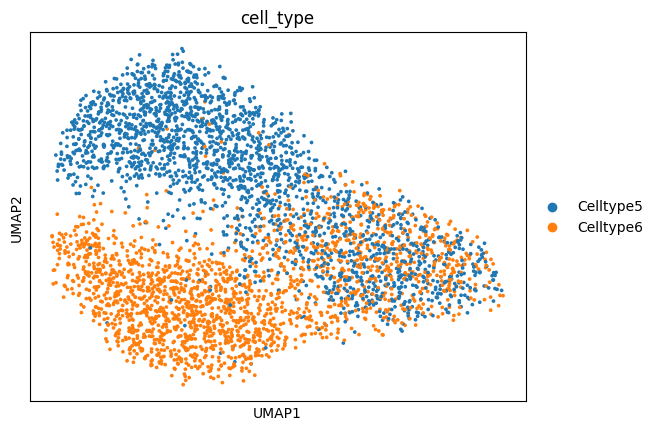

In [62]:
sc.pp.neighbors(adata, n_neighbors=5, use_rep='jepa_emb')
sc.tl.umap(adata)

# Plot the UMAP
sc.pl.umap(adata, color='cell_type')

### 5.2.3 Logistic regression

In [63]:
classification_metrics(adata, label_col='cell_type', classifier='logistic')

Test Accuracy: 0.87
Test F1 Score: 0.87
Train Accuracy: 0.88
Train F1 Score: 0.88


{'test_accuracy': 0.8731884057971014,
 'test_f1': 0.8731634320694629,
 'train_accuracy': 0.8816067653276956,
 'train_f1': 0.8816163839404368}

### 5.2.4 KNN

In [64]:
classification_metrics(adata, label_col='cell_type', classifier='knn', n_neighbors=5)

Test Accuracy: 0.86
Test F1 Score: 0.86
Train Accuracy: 0.91
Train F1 Score: 0.91


{'test_accuracy': 0.857487922705314,
 'test_f1': 0.8574895856718802,
 'train_accuracy': 0.9127151917849592,
 'train_f1': 0.9126928201354862}

### 5.2.5 nmi&ari

In [65]:
clustering_metrics(adata,label_col='cell_type')

NMI (Normalized Mutual Information): 0.0002621755321478895
ARI (Adjusted Rand Index): 0.0002752815035292115


{'nmi': 0.0002621755321478895, 'ari': 0.0002752815035292115}

## 5.3 Cell Type weighted_average

In [66]:
params['emb']['retrieve_cell'] = True
params['emb']['retrieve_niche'] = False
params['emb']['retrieve_gene'] = False
params['emb']['weighted_average']=True
params['emb']['average']=False
params['emb']['cls']=False
params['data']['just_cell'] = True
params['data']['just_neighborhood'] = False
adata = evaluation(params, train_dataset, test_dataset)

INFO:root:GeneTransformerEncoder(
  (gene_embed): Embedding(1108, 768, padding_idx=0)
  (seg_embed): Embedding(3, 768, padding_idx=0)
  (blocks): ModuleList(
    (0-2): 3 x Block(
      (norm1): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
      (attn): Attention(
        (qkv): Linear(in_features=768, out_features=2304, bias=True)
        (attn_drop): Dropout(p=0.0, inplace=False)
        (proj): Linear(in_features=768, out_features=768, bias=True)
        (proj_drop): Dropout(p=0.0, inplace=False)
      )
      (drop_path): Identity()
      (norm2): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
      (mlp): MLP(
        (fc1): Linear(in_features=768, out_features=3072, bias=True)
        (act): GELU(approximate='none')
        (fc2): Linear(in_features=3072, out_features=768, bias=True)
        (drop): Dropout(p=0.0, inplace=False)
      )
    )
  )
  (norm): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
)


/nfs/team361/mv10/.jepa/lib/python3.10/site-packages/torch/utils/data/dataloader.py:558: UserWarning: This DataLoader will create 18 worker processes in total. Our suggested max number of worker in current system is 12, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(_create_warning_msg(


INFO:root:loaded pretrained encoder from epoch 15 with msg: <All keys matched successfully>
INFO:root:loaded pretrained encoder from epoch 15 with msg: <All keys matched successfully>
['encoder', 'predictor', 'target_encoder', 'opt', 'scaler', 'epoch', 'loss', 'batch_size', 'world_size', 'lr']
INFO:root:loaded pretrained encoder from epoch 15 with msg: <All keys matched successfully>


/usr/lib/python3.10/multiprocessing/popen_fork.py:66: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  self.pid = os.fork()
147it [00:01, 132.26it/s]/usr/lib/python3.10/multiprocessing/popen_fork.py:66: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  self.pid = os.fork()
166it [00:01, 103.44it/s]
42it [00:00, 69.90it/s]
... storing 'split' as categorical
... storing 'label_name' as categorical
... storing 'retrieve_label' as categorical
... storing 'cell_type' as categorical


AnnData has been successfully saved at: logs/Simulated_data_pred_depth_1_pred_emb_dim_768_enc_depth_3_n_targets_4_n_contexts_1_target_mask_size_19_context_mask_size_361_num_epochs_15_just_cell_subset_Celltype5_Celltype6/extracted_features/cell_embedding_weighted_average.h5ad


### 5.3.1 Feature Analysis

In [67]:
similarity_matrix = cosine_similarity(adata.obsm['jepa_emb'])
similarity_matrix

array([[1.0000001 , 0.99872696, 0.99844575, ..., 0.998153  , 0.99877626,
        0.9986372 ],
       [0.99872696, 1.0000001 , 0.99849546, ..., 0.99824286, 0.99881744,
        0.998765  ],
       [0.99844575, 0.99849546, 1.0000001 , ..., 0.99816823, 0.99851435,
        0.9983939 ],
       ...,
       [0.998153  , 0.99824286, 0.99816823, ..., 1.0000002 , 0.9983182 ,
        0.99824697],
       [0.99877626, 0.99881744, 0.99851435, ..., 0.9983182 , 1.0000005 ,
        0.99867034],
       [0.9986372 , 0.998765  , 0.9983939 , ..., 0.99824697, 0.99867034,
        0.99999994]], dtype=float32)

### 5.3.2 Umap

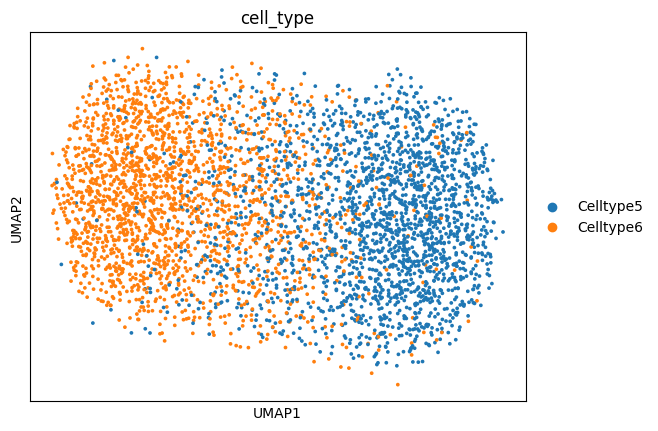

In [68]:
sc.pp.neighbors(adata, n_neighbors=5, use_rep='jepa_emb')
sc.tl.umap(adata)

#Plot the UMAP
sc.pl.umap(adata, color='cell_type')

### 5.3.3 Logistic regression

In [69]:
classification_metrics(adata, label_col='cell_type', classifier='logistic')

Test Accuracy: 0.94
Test F1 Score: 0.94
Train Accuracy: 0.97
Train F1 Score: 0.97


{'test_accuracy': 0.9432367149758454,
 'test_f1': 0.9432361354063474,
 'train_accuracy': 0.9716097855632739,
 'train_f1': 0.9716135636144021}

### 5.3.4 KNN

In [70]:
classification_metrics(adata, label_col='cell_type', classifier='knn', n_neighbors=5)

Test Accuracy: 0.87
Test F1 Score: 0.87
Train Accuracy: 0.92
Train F1 Score: 0.92


{'test_accuracy': 0.8707729468599034,
 'test_f1': 0.870771627322065,
 'train_accuracy': 0.9154334038054969,
 'train_f1': 0.9154472961610215}

### 5.3.5 nmi&ari

In [71]:
clustering_metrics(adata,label_col='cell_type')

NMI (Normalized Mutual Information): 5.504422565807316e-05
ARI (Adjusted Rand Index): -4.6445623137152596e-05


{'nmi': 5.504422565807316e-05, 'ari': -4.6445623137152596e-05}

### 5.3.5 nmi&ari on pca

In [72]:
import scib_metrics as sm
reduced_embeddings=sc.pp.pca(adata.obsm['jepa_emb'],n_comps=2)
sm.nmi_ari_cluster_labels_kmeans(reduced_embeddings, adata.obs['cell_type'])

{'nmi': 0.45424119698393417, 'ari': 0.41878093557329693}

## 5.4 Retrieve Gene

In [73]:
params['emb']['retrieve_cell'] = False
params['emb']['retrieve_niche'] = False
params['emb']['retrieve_gene'] = True
params['emb']['weighted_average']=False
params['emb']['average']=True
params['emb']['cls']=False
params['data']['just_cell'] = True
params['data']['just_neighborhood'] = False
params['emb']['gene_id']=332 #change this for different value to get different gene_emb'

adata = evaluation(params, train_dataset, test_dataset)

INFO:root:GeneTransformerEncoder(
  (gene_embed): Embedding(1108, 768, padding_idx=0)
  (seg_embed): Embedding(3, 768, padding_idx=0)
  (blocks): ModuleList(
    (0-2): 3 x Block(
      (norm1): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
      (attn): Attention(
        (qkv): Linear(in_features=768, out_features=2304, bias=True)
        (attn_drop): Dropout(p=0.0, inplace=False)
        (proj): Linear(in_features=768, out_features=768, bias=True)
        (proj_drop): Dropout(p=0.0, inplace=False)
      )
      (drop_path): Identity()
      (norm2): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
      (mlp): MLP(
        (fc1): Linear(in_features=768, out_features=3072, bias=True)
        (act): GELU(approximate='none')
        (fc2): Linear(in_features=3072, out_features=768, bias=True)
        (drop): Dropout(p=0.0, inplace=False)
      )
    )
  )
  (norm): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
)


/nfs/team361/mv10/.jepa/lib/python3.10/site-packages/torch/utils/data/dataloader.py:558: UserWarning: This DataLoader will create 18 worker processes in total. Our suggested max number of worker in current system is 12, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(_create_warning_msg(


INFO:root:loaded pretrained encoder from epoch 15 with msg: <All keys matched successfully>
INFO:root:loaded pretrained encoder from epoch 15 with msg: <All keys matched successfully>
['encoder', 'predictor', 'target_encoder', 'opt', 'scaler', 'epoch', 'loss', 'batch_size', 'world_size', 'lr']
INFO:root:loaded pretrained encoder from epoch 15 with msg: <All keys matched successfully>


/usr/lib/python3.10/multiprocessing/popen_fork.py:66: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  self.pid = os.fork()
156it [00:01, 153.19it/s]/usr/lib/python3.10/multiprocessing/popen_fork.py:66: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  self.pid = os.fork()
166it [00:01, 100.93it/s]
42it [00:00, 78.99it/s]
... storing 'split' as categorical
... storing 'label_name' as categorical
... storing 'retrieve_label' as categorical
... storing 'cell_type' as categorical


AnnData has been successfully saved at: logs/Simulated_data_pred_depth_1_pred_emb_dim_768_enc_depth_3_n_targets_4_n_contexts_1_target_mask_size_19_context_mask_size_361_num_epochs_15_just_cell_subset_Celltype5_Celltype6/extracted_features/gene_embedding_gene_id_332_average.h5ad


### 5.4.1 Feature Analysis

In [74]:
similarity_matrix = cosine_similarity(adata.obsm['jepa_emb'])
similarity_matrix

array([[0.        , 0.        , 0.        , ..., 0.        , 0.        ,
        0.        ],
       [0.        , 1.        , 0.        , ..., 0.        , 0.99993026,
        0.        ],
       [0.        , 0.        , 0.        , ..., 0.        , 0.        ,
        0.        ],
       ...,
       [0.        , 0.        , 0.        , ..., 0.        , 0.        ,
        0.        ],
       [0.        , 0.99993026, 0.        , ..., 0.        , 1.0000001 ,
        0.        ],
       [0.        , 0.        , 0.        , ..., 0.        , 0.        ,
        0.        ]], dtype=float32)

In [75]:
adata = adata[adata.obs['gene_count']!=0]

### 5.4.2 Umap

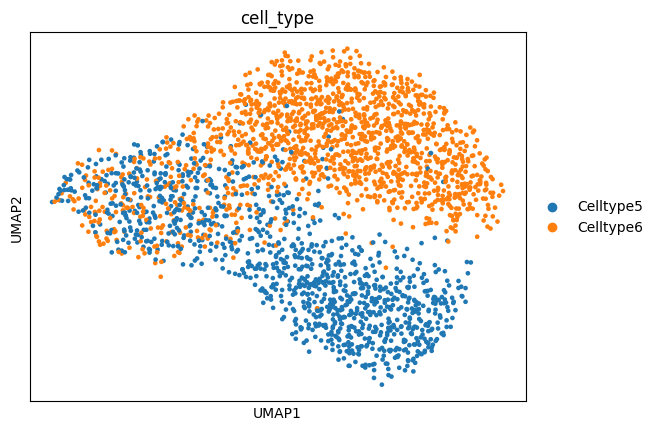

In [76]:
sc.pp.neighbors(adata, n_neighbors=5, use_rep='jepa_emb')
sc.tl.umap(adata)

# Plot the UMAP
sc.pl.umap(adata, color='cell_type')